# Support tickets: escalation (classification) and resolution time (regression)

## 1. Problem framing
* **Experiment A:** predict `escalated` (1 = ticket was escalated) from ticket details known at creation, so likely escalations can be routed to senior staff early. Primary metric: **F1**, because escalations are the minority class and both missed escalations and false alarms have a cost.
* **Experiment B:** predict `resolution_time_hours` for staffing and SLA planning. Primary metric: **MAE**, which is in hours and not dominated by a few very long tickets.
* **Features (both):** `complexity_score`, `team_experience_years`, `customer_tenure_months` (numeric); `priority`, `channel` (categorical). `ticket_id` is dropped because it is only an identifier.

## 2. Preprocessing
* **Numeric:** median imputation (robust to skew), then standard scaling (logistic regression, k-NN and ridge are sensitive to feature scale).
* **Categorical:** most-frequent imputation, then one-hot encoding with `handle_unknown="ignore"` so a category not seen in training does not break prediction.
* Everything is inside a `ColumnTransformer` + `Pipeline`, so the medians, scaling and categories are learned from the training part of each fold only.

## 3. Validation strategy
* 20% of the data is held out as a test set and not touched until the end.
* All models are compared with the same 5-fold CV on the training set: `StratifiedKFold` for A, `KFold` for B, fixed seed.
* Hyperparameters are tuned with `GridSearchCV` on the same folds. The chosen pipeline is evaluated on the test set once.

In [13]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, f1_score, precision_score, recall_score)

SEED = 42

def find(name):
    for p in (os.path.join("data", name), name):
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"{name} not found in ./data or current folder")

clf_df = pd.read_csv(find("classification_escalation.csv"))
reg_df = pd.read_csv(find("resolution_time_regression.csv"))
display(clf_df.head(), reg_df.head())

,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,T0000,2.0,15.0,Medium,Email,61.818896,0
1,T0001,9.0,6.0,Critical,Chat,110.024317,0
2,T0002,10.0,8.0,High,Phone,36.311244,0
3,T0003,2.0,1.0,Medium,Phone,85.127855,0
4,T0004,8.0,14.0,Medium,Chat,18.225059,0


,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,resolution_time_hours
0,R0000,7.0,10.0,Medium,Chat,32.638377,8.38724
1,R0001,4.0,15.0,Medium,Chat,45.273760,0.50000
2,R0002,4.0,13.0,Low,Portal,44.878323,0.50000
3,R0003,1.0,10.0,High,Phone,40.095034,0.50000
4,R0004,3.0,15.0,Low,Portal,47.451134,0.50000


In [13]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, f1_score, precision_score, recall_score)

SEED = 42

def find(name):
    for p in (os.path.join("data", name), name):
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"{name} not found in ./data or current folder")

clf_df = pd.read_csv(find("classification_escalation.csv"))
reg_df = pd.read_csv(find("resolution_time_regression.csv"))
display(clf_df.head(), reg_df.head())

,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,T0000,2.0,15.0,Medium,Email,61.818896,0
1,T0001,9.0,6.0,Critical,Chat,110.024317,0
2,T0002,10.0,8.0,High,Phone,36.311244,0
3,T0003,2.0,1.0,Medium,Phone,85.127855,0
4,T0004,8.0,14.0,Medium,Chat,18.225059,0


,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,resolution_time_hours
0,R0000,7.0,10.0,Medium,Chat,32.638377,8.38724
1,R0001,4.0,15.0,Medium,Chat,45.273760,0.50000
2,R0002,4.0,13.0,Low,Portal,44.878323,0.50000
3,R0003,1.0,10.0,High,Phone,40.095034,0.50000
4,R0004,3.0,15.0,Low,Portal,47.451134,0.50000


## 4. Data check

In [2]:
for name, df in [("Classification", clf_df), ("Regression", reg_df)]:
    print(f"{name}: shape {df.shape}, duplicate ticket_ids: {df['ticket_id'].duplicated().sum()}")
    print(df.isna().sum()[lambda s: s > 0].to_string(), "\n")
print("Escalation balance:")
print(clf_df["escalated"].value_counts().to_frame("count").assign(share=lambda d: (d["count"] / d["count"].sum()).round(3)))
display(clf_df.describe().T, reg_df.describe().T)

Classification: shape (900, 7), duplicate ticket_ids: 0
complexity_score          22
team_experience_years     36
priority                  13
channel                    9
customer_tenure_months    31 

Regression: shape (800, 7), duplicate ticket_ids: 0
complexity_score          16
team_experience_years     24
customer_tenure_months    20 

Escalation balance:
           count  share
escalated              
0            709  0.788
1            191  0.212


,count,mean,std,min,25%,50%,75%,max
complexity_score,878.0,5.523918,2.869451,1.000000,3.00000,5.000000,8.000000,10.0
team_experience_years,864.0,7.482639,4.528235,0.000000,4.00000,8.000000,11.000000,15.0
customer_tenure_months,869.0,40.018745,26.126088,1.065286,20.08543,34.649084,54.269475,120.0
escalated,900.0,0.212222,0.409109,0.000000,0.00000,0.000000,0.000000,1.0


,count,mean,std,min,25%,50%,75%,max
complexity_score,784.0,5.545918,2.849200,1.000000,3.000000,6.000000,8.000000,10.000000
team_experience_years,776.0,7.496134,4.479342,0.000000,4.000000,8.000000,11.000000,15.000000
customer_tenure_months,780.0,39.577416,26.510500,0.884553,19.697823,33.979577,54.299824,120.000000
resolution_time_hours,800.0,5.873160,4.144974,0.500000,2.631319,5.387386,8.345903,27.488229


# Experiment A: classification

Stratified split: the class ratio stays the same in train and test.

In [14]:
y_c = clf_df["escalated"].astype(int)
X_c = clf_df.drop(columns=["ticket_id", "escalated"])
num_cols_c = X_c.select_dtypes(include="number").columns.tolist()
cat_cols_c = X_c.select_dtypes(exclude="number").columns.tolist()

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_c, y_c, test_size=0.20, stratify=y_c, random_state=SEED)
print("Escalation rate  full: %.3f | train: %.3f | test: %.3f" % (y_c.mean(), yc_train.mean(), yc_test.mean()))
print("Train:", len(Xc_train), "| Test:", len(Xc_test))

Escalation rate  full: 0.212 | train: 0.212 | test: 0.211
Train: 720 | Test: 180


### Baseline comparison (default settings, 5-fold stratified CV, F1)

In [4]:
def make_pipe(model, num_cols, cat_cols):
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    categorical = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    prep = ColumnTransformer([("num", numeric, num_cols), ("cat", categorical, cat_cols)])
    return Pipeline([("prep", prep), ("model", model)])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

clf_candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "k-NN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
}
scoring_c = {"f1": "f1", "precision": "precision", "recall": "recall", "accuracy": "accuracy"}

rows, fold_f1 = [], {}
for name, m in clf_candidates.items():
    res = cross_validate(make_pipe(m, num_cols_c, cat_cols_c), Xc_train, yc_train, cv=skf, scoring=scoring_c)
    fold_f1[name] = res["test_f1"]
    rows.append({"Model": name, "F1 mean": res["test_f1"].mean(), "F1 std": res["test_f1"].std(),
                 "Precision": res["test_precision"].mean(), "Recall": res["test_recall"].mean(),
                 "Accuracy": res["test_accuracy"].mean()})
cv_clf_default = pd.DataFrame(rows).set_index("Model").round(4)
display(cv_clf_default)
display(pd.DataFrame(fold_f1, index=[f"fold {i}" for i in range(1, 6)]).round(4))

,F1 mean,F1 std,Precision,Recall,Accuracy
Model,,,,,
Logistic Regression,0.3927,0.0627,0.6240,0.2882,0.8125
k-NN,0.3608,0.0503,0.5617,0.2677,0.8000
Decision Tree,0.3307,0.0581,0.3183,0.3467,0.7042


,Logistic Regression,k-NN,Decision Tree
fold 1,0.3913,0.3673,0.4000
fold 2,0.3256,0.3256,0.2295
fold 3,0.3636,0.4255,0.3226
fold 4,0.3721,0.2857,0.3729
fold 5,0.5106,0.4000,0.3284


### Tuning (GridSearchCV, F1, same folds)
* Logistic regression: `C` in {0.01, 0.1, 1, 10, 100}; `class_weight` in {None, balanced}.
* k-NN: `n_neighbors` in {3, 5, 7, 11, 15, 21}; `weights` in {uniform, distance}.
* Decision tree: `max_depth` in {3, 5, 7, 10, None}; `min_samples_leaf` in {1, 5, 10, 20}.

In [5]:
grids_c = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100], "model__class_weight": [None, "balanced"]},
    "k-NN": {"model__n_neighbors": [3, 5, 7, 11, 15, 21], "model__weights": ["uniform", "distance"]},
    "Decision Tree": {"model__max_depth": [3, 5, 7, 10, None], "model__min_samples_leaf": [1, 5, 10, 20]},
}
tuned_c, rows = {}, []
for name, m in clf_candidates.items():
    gs = GridSearchCV(make_pipe(m, num_cols_c, cat_cols_c), grids_c[name], scoring="f1", cv=skf, n_jobs=-1)
    gs.fit(Xc_train, yc_train)
    tuned_c[name] = gs
    i = gs.best_index_
    rows.append({"Model": name, "Best params": {k.replace("model__", ""): v for k, v in gs.best_params_.items()},
                 "CV F1 mean": float(gs.cv_results_["mean_test_score"][i]),
                 "CV F1 std": float(gs.cv_results_["std_test_score"][i])})
tuned_clf_table = pd.DataFrame(rows).set_index("Model")
tuned_clf_table[["CV F1 mean", "CV F1 std"]] = tuned_clf_table[["CV F1 mean", "CV F1 std"]].round(4)
display(tuned_clf_table)

best_name_c = tuned_clf_table["CV F1 mean"].astype(float).idxmax()
best_clf = tuned_c[best_name_c].best_estimator_
i = tuned_c[best_name_c].best_index_
fold_scores = [tuned_c[best_name_c].cv_results_[f"split{k}_test_score"][i] for k in range(5)]
print("Selected:", best_name_c)
print("Per-fold F1:", np.round(fold_scores, 4), "| range:", round(max(fold_scores) - min(fold_scores), 4))

,Best params,CV F1 mean,CV F1 std
Model,,,
Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",0.5200,0.0423
k-NN,"{'n_neighbors': 3, 'weights': 'uniform'}",0.3906,0.0644
Decision Tree,"{'max_depth': 7, 'min_samples_leaf': 20}",0.3810,0.0800


Selected: Logistic Regression
Per-fold F1: [0.5435 0.4762 0.5714 0.4634 0.5455] | range: 0.108


### Test set evaluation (once)

              precision    recall  f1-score   support

           0      0.914     0.824     0.867       142
           1      0.519     0.711     0.600        38

    accuracy                          0.800       180
   macro avg      0.717     0.767     0.733       180
weighted avg      0.831     0.800     0.810       180

CV F1 for comparison: 0.520 +/- 0.042


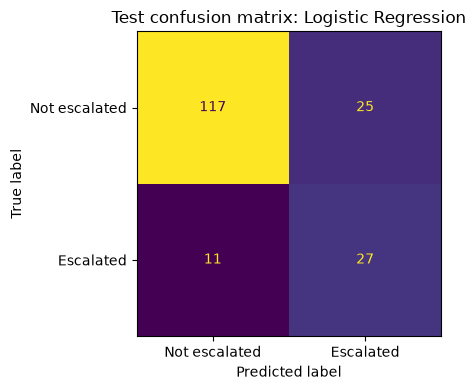

False positives: 25 (flagged, did not escalate) | precision 0.519
False negatives: 11 (escalated, not flagged)    | recall 0.711


In [6]:
pred_c = best_clf.predict(Xc_test)
cm = confusion_matrix(yc_test, pred_c)
tn, fp, fn, tp = cm.ravel()

print(classification_report(yc_test, pred_c, digits=3))
print(f"CV F1 for comparison: {tuned_clf_table.loc[best_name_c, 'CV F1 mean']:.3f} +/- {tuned_clf_table.loc[best_name_c, 'CV F1 std']:.3f}")

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Not escalated", "Escalated"]).plot(ax=ax, colorbar=False)
ax.set_title(f"Test confusion matrix: {best_name_c}"); plt.tight_layout(); plt.show()

print(f"False positives: {fp} (flagged, did not escalate) | precision {tp/(tp+fp):.3f}")
print(f"False negatives: {fn} (escalated, not flagged)    | recall {tp/(tp+fn):.3f}")

# Experiment B: regression

Outliers are inspected on the training data only and kept, since long tickets will also occur in production.

Train: (640, 5) | Test: (160, 5)
Skewness: 1.16 | max: 26.6 h
IQR outliers: 8 of 640 (1.2%), all above 16.5 h
Tickets at the minimum value (0.5 h): 58 (9.1%)


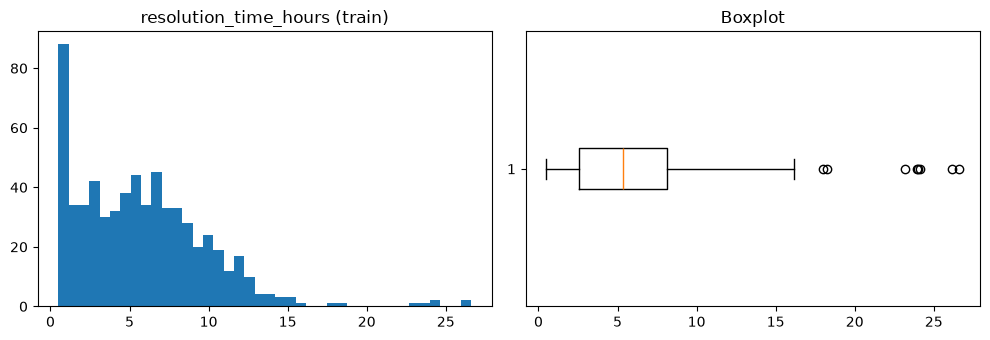

In [7]:
y_r = reg_df["resolution_time_hours"]
X_r = reg_df.drop(columns=["ticket_id", "resolution_time_hours"])
num_cols_r = X_r.select_dtypes(include="number").columns.tolist()
cat_cols_r = X_r.select_dtypes(exclude="number").columns.tolist()

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_r, y_r, test_size=0.20, random_state=SEED)
print("Train:", Xr_train.shape, "| Test:", Xr_test.shape)

q1, q3 = yr_train.quantile([0.25, 0.75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = int(((yr_train < lo) | (yr_train > hi)).sum())
floor = yr_train.min()
n_floor = int((yr_train == floor).sum())
print(f"Skewness: {yr_train.skew():.2f} | max: {yr_train.max():.1f} h")
print(f"IQR outliers: {n_out} of {len(yr_train)} ({n_out/len(yr_train):.1%}), all above {hi:.1f} h")
print(f"Tickets at the minimum value ({floor} h): {n_floor} ({n_floor/len(yr_train):.1%})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(yr_train, bins=40); axes[0].set_title("resolution_time_hours (train)")
axes[1].boxplot(yr_train, vert=False); axes[1].set_title("Boxplot")
plt.tight_layout(); plt.show()

### Baseline comparison (default settings, 5-fold CV, MAE; RMSE also recorded)

In [8]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
reg_candidates = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(random_state=SEED),
}
scoring_r = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

rows, fold_mae = [], {}
for name, m in reg_candidates.items():
    res = cross_validate(make_pipe(m, num_cols_r, cat_cols_r), Xr_train, yr_train, cv=kf, scoring=scoring_r)
    mae, rmse = -res["test_mae"], -res["test_rmse"]
    fold_mae[name] = mae
    rows.append({"Model": name, "MAE mean": mae.mean(), "MAE std": mae.std(), "RMSE mean": rmse.mean(), "RMSE std": rmse.std()})
cv_reg_default = pd.DataFrame(rows).set_index("Model").round(4)
display(cv_reg_default)
display(pd.DataFrame(fold_mae, index=[f"fold {i}" for i in range(1, 6)]).round(4))

,MAE mean,MAE std,RMSE mean,RMSE std
Model,,,,
Linear Regression,2.0351,0.1717,2.9606,0.5845
Ridge,2.0351,0.1714,2.9605,0.5835
Decision Tree,3.2391,0.0538,4.5876,0.3749


,Linear Regression,Ridge,Decision Tree
fold 1,2.3419,2.3408,3.2412
fold 2,1.8171,1.8163,3.1685
fold 3,1.9651,1.9672,3.2165
fold 4,2.0436,2.0449,3.3338
fold 5,2.0080,2.0064,3.2355


### Tuning (GridSearchCV, MAE, same folds)
* Ridge: `alpha` from 0.001 to 1000 (13 log-spaced values).
* Decision tree: `max_depth` in {2, 3, 4, 5, 6, 8, 10, None}; `min_samples_leaf` in {1, 5, 10, 20}.
* Linear regression has nothing to tune and stays as the reference.

In [9]:
grids_r = {
    "Ridge": (Ridge(), {"model__alpha": np.logspace(-3, 3, 13)}),
    "Decision Tree": (DecisionTreeRegressor(random_state=SEED),
                      {"model__max_depth": [2, 3, 4, 5, 6, 8, 10, None], "model__min_samples_leaf": [1, 5, 10, 20]}),
}
tuned_r, rows = {}, []
for name, (m, g) in grids_r.items():
    gs = GridSearchCV(make_pipe(m, num_cols_r, cat_cols_r), g, scoring="neg_mean_absolute_error", cv=kf, n_jobs=-1)
    gs.fit(Xr_train, yr_train)
    tuned_r[name] = gs
    i = gs.best_index_
    rows.append({"Model": name,
                 "Best params": {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                                 for k, v in gs.best_params_.items()},
                 "CV MAE mean": float(-gs.cv_results_["mean_test_score"][i]),
                 "CV MAE std": float(gs.cv_results_["std_test_score"][i])})
lin = cv_reg_default.loc["Linear Regression"]
rows.append({"Model": "Linear Regression", "Best params": {}, "CV MAE mean": float(lin["MAE mean"]), "CV MAE std": float(lin["MAE std"])})
tuned_reg_table = pd.DataFrame(rows).set_index("Model")
tuned_reg_table[["CV MAE mean", "CV MAE std"]] = tuned_reg_table[["CV MAE mean", "CV MAE std"]].round(4)
display(tuned_reg_table)

best_name_r = tuned_reg_table["CV MAE mean"].astype(float).idxmin()
if best_name_r == "Linear Regression":
    best_reg = make_pipe(LinearRegression(), num_cols_r, cat_cols_r).fit(Xr_train, yr_train)
else:
    best_reg = tuned_r[best_name_r].best_estimator_
print("Selected:", best_name_r)

,Best params,CV MAE mean,CV MAE std
Model,,,
Ridge,{'alpha': 0.3162},2.0351,0.1716
Decision Tree,"{'max_depth': 6, 'min_samples_leaf': 20}",2.3643,0.0891
Linear Regression,{},2.0351,0.1717


Selected: Ridge


### Test set evaluation (once)

Ridge: test MAE 2.230 h | test RMSE 3.403 h | CV MAE 2.035 +/- 0.172 h
Baseline (always predict training median): MAE 3.273 h


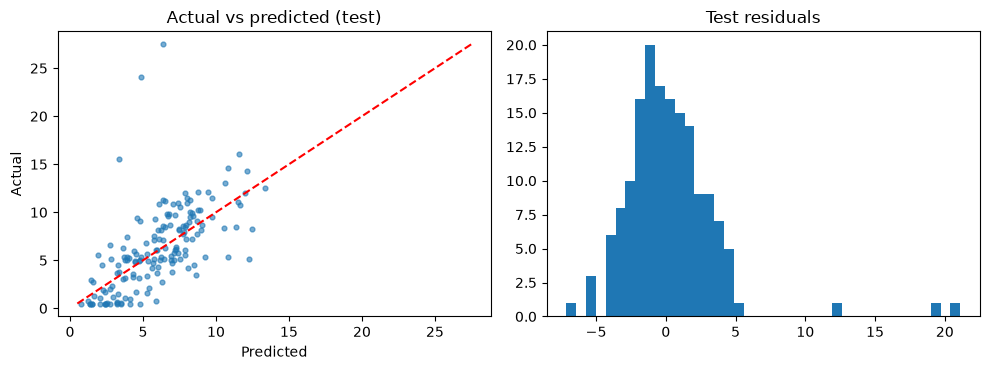

Worst 5% of test tickets (8): 61% of squared error, 23% of absolute error


In [10]:
pred_r = best_reg.predict(Xr_test)
test_mae = mean_absolute_error(yr_test, pred_r)
test_rmse = np.sqrt(mean_squared_error(yr_test, pred_r))
cv_mae = float(tuned_reg_table.loc[best_name_r, "CV MAE mean"])
cv_std = float(tuned_reg_table.loc[best_name_r, "CV MAE std"])
median_mae = mean_absolute_error(yr_test, np.full(len(yr_test), yr_train.median()))

print(f"{best_name_r}: test MAE {test_mae:.3f} h | test RMSE {test_rmse:.3f} h | CV MAE {cv_mae:.3f} +/- {cv_std:.3f} h")
print(f"Baseline (always predict training median): MAE {median_mae:.3f} h")

resid = yr_test.values - pred_r
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(pred_r, yr_test, s=12, alpha=.6)
lim = [min(pred_r.min(), yr_test.min()), max(pred_r.max(), yr_test.max())]
axes[0].plot(lim, lim, "r--"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title("Actual vs predicted (test)")
axes[1].hist(resid, bins=40); axes[1].set_title("Test residuals")
plt.tight_layout(); plt.show()

big = np.argsort(-np.abs(resid))[:max(1, int(0.05 * len(resid)))]
sq_share = (resid[big] ** 2).sum() / (resid ** 2).sum()
abs_share = np.abs(resid[big]).sum() / np.abs(resid).sum()
print(f"Worst 5% of test tickets ({len(big)}): {sq_share:.0%} of squared error, {abs_share:.0%} of absolute error")

### MAE vs RMSE

In [11]:
cmp = cv_reg_default[["MAE mean", "RMSE mean"]].copy()
cmp["MAE rank"] = cmp["MAE mean"].round(3).rank(method="min").astype(int)
cmp["RMSE rank"] = cmp["RMSE mean"].round(3).rank(method="min").astype(int)
display(cmp)

,MAE mean,RMSE mean,MAE rank,RMSE rank
Model,,,,
Linear Regression,2.0351,2.9606,1,2
Ridge,2.0351,2.9605,1,1
Decision Tree,3.2391,4.5876,3,3


# 5. Report

## 5.1 Models and search spaces
* **A:** logistic regression (linear baseline), k-NN (local structure), decision tree (non-linear effects and interactions). Search spaces are listed above each tuning cell.
* **B:** linear regression (baseline), ridge (linear with shrinkage), decision tree regressor. Search spaces are listed above the tuning cell.

## 5.2 Leakage prevention
* `ticket_id` is removed.
* The split happens before any fitting. The test set never reaches an imputer, scaler, encoder or grid search.
* Imputation, scaling and encoding are pipeline steps, so each CV fold fits them on its own training portion only.
* Model selection uses CV scores only. The test set is scored once per experiment.

## 5.3 Reflection questions

**1. Why stratify the classification split?**
Only about a fifth of tickets escalate. A random split can leave train and test with different escalation rates, so F1 would partly reflect the split instead of the model. Stratifying keeps the rate the same in every split and fold, and guarantees each fold has enough positive cases.

**2. Why must preprocessing be inside the pipeline?**
Medians, scaling statistics and category lists are learned from data. If they are computed on the full dataset before CV, the validation rows influence them, and the CV score comes out too optimistic. Inside the pipeline they are fitted on the training part of each fold only and then applied to the validation part, which is what happens with new tickets in production.

**3. What does fold variability tell you?**
It shows how much the score depends on which tickets ended up in training and validation. A small standard deviation means stable performance. A large one points to a high-variance model, a small dataset, or outliers landing in particular folds. If two models differ by less than about one fold standard deviation, that difference is not reliable evidence that one is better, so the simpler model is preferred.

**4. Why evaluate the test set only once?**
The test set is only an unbiased estimate of future performance while no decision depends on it. Each time we look at the test score and then change a model or setting, we tune to the test set and the estimate becomes optimistic.

**5. What deployment constraints might change the choice?**
* **Speed:** k-NN keeps the training data and computes distances at prediction time, so it is the slowest to serve.
* **Explainability:** staff may need to know why a ticket was flagged, which favours logistic regression, ridge or a shallow tree.
* **Error costs:** if a missed escalation costs much more than a false alarm, the decision threshold should be lowered to favour recall.
* **Feature availability:** every feature must be known when the ticket is created.
* **Drift:** ticket mix and team experience change over time, so the model needs monitoring and retraining.

In [12]:
display(Markdown("## 5.4 CV results"))
print("Classification (F1, 5-fold stratified CV): default vs tuned")
display(cv_clf_default[["F1 mean", "F1 std"]].join(tuned_clf_table[["CV F1 mean", "CV F1 std", "Best params"]].rename(columns=lambda c: "tuned " + c)))
print("Regression (MAE in hours, 5-fold CV): default vs tuned")
display(cv_reg_default[["MAE mean", "MAE std"]].join(tuned_reg_table[["CV MAE mean", "CV MAE std", "Best params"]].rename(columns=lambda c: "tuned " + c)))

cv_f1 = float(tuned_clf_table.loc[best_name_c, "CV F1 mean"]); sd_f1 = float(tuned_clf_table.loc[best_name_c, "CV F1 std"])
t_f1 = float(f1_score(yc_test, pred_c)); t_p = float(precision_score(yc_test, pred_c)); t_r = float(recall_score(yc_test, pred_c))
ridge_row = tuned_reg_table.loc["Ridge"]; lin_row = tuned_reg_table.loc["Linear Regression"]
tie = abs(float(ridge_row["CV MAE mean"]) - float(lin_row["CV MAE mean"])) < 0.005
tree_gap = float(tuned_reg_table.loc["Decision Tree", "CV MAE mean"]) - float(tuned_reg_table.loc[best_name_r, "CV MAE mean"])
top_mae = set(cmp.index[cmp["MAE mean"] < cmp["MAE mean"].min() + 0.005]); top_rmse = set(cmp.index[cmp["RMSE mean"] < cmp["RMSE mean"].min() + 0.005]); same_rank = bool(top_mae & top_rmse)

display(Markdown(f'''
## 5.5 Final results
| Experiment | Model | CV (mean ± std) | Test (one evaluation) |
|---|---|---|---|
| A: escalation | {best_name_c} | F1 {cv_f1:.3f} ± {sd_f1:.3f} | F1 {t_f1:.3f} (precision {t_p:.3f}, recall {t_r:.3f}) |
| B: resolution time | {best_name_r} | MAE {cv_mae:.3f} ± {cv_std:.3f} h | MAE {test_mae:.3f} h, RMSE {test_rmse:.3f} h |

## 5.6 Model justification
**A:** {best_name_c} had the best tuned CV F1, ahead of the other two by {cv_f1 - float(tuned_clf_table["CV F1 mean"].drop(best_name_c).max()):.3f} or more, which is {"larger" if cv_f1 - float(tuned_clf_table["CV F1 mean"].drop(best_name_c).max()) > sd_f1 else "not larger"} than its fold standard deviation. The test F1 ({t_f1:.3f}) is above the CV mean ({cv_f1:.3f}); with only {int(yc_test.sum())} escalated tickets in the test set, a gap of this size is within normal sampling noise, so CV is the safer estimate of future performance. Precision is low ({t_p:.3f}): about half of flagged tickets would not have escalated.

**B:** {best_name_r} was selected. {"Ridge and linear regression are tied (their CV MAE differs by less than 0.005 h), so the choice between them is a tie-break, not evidence that ridge is better. The tuned alpha is small, so ridge behaves almost exactly like plain linear regression." if tie else "The linear models are not tied."} The tuned decision tree is {tree_gap:.2f} h worse in MAE. The test MAE ({test_mae:.3f} h) is close to the CV MAE ({cv_mae:.3f} h) and clearly better than the median baseline ({median_mae:.3f} h).

## 5.7 Outliers, MAE and RMSE
Squaring makes RMSE weight large misses much more than MAE does. On the test set the worst 5% of tickets account for {sq_share:.0%} of the squared error but only {abs_share:.0%} of the absolute error, so RMSE ({test_rmse:.2f} h) is far above MAE ({test_mae:.2f} h). A model that fits typical tickets well but misses a few very long ones can win on MAE and lose on RMSE, and a model that chases the long tickets can do the reverse. In this data the default CV ranking is {"the same under both metrics (linear and ridge are effectively tied, and both beat the tree)" if same_rank else "different between the two metrics"}, so here the choice of metric matters little. It would matter more if very late tickets carry a heavy SLA penalty.

## 5.8 Limitations
* One train/test split of a few hundred tickets; the test metrics carry real sampling error (for example, only {int(yc_test.sum())} positives in the classification test set).
* Only five features. Escalation F1 is modest, so a lot of what drives escalation is not captured.
* About {n_floor/len(yr_train):.0%} of resolution times sit exactly at the minimum value ({floor} h), which looks like a floor in how times are recorded. A linear model can predict below it.
* F1 at the default 0.5 threshold ignores the real costs of false positives and false negatives. The threshold should be set from those costs.
* The target is skewed and MAE treats a 1 h error the same on a 1 h ticket and a 20 h ticket. A log transform or quantile model could be tried.
* Only simple models were compared. Ensembles were outside the brief and may do better.
* No check of calibration, drift over time, or performance across customer segments.
'''))

## 5.4 CV results

Classification (F1, 5-fold stratified CV): default vs tuned


,F1 mean,F1 std,tuned CV F1 mean,tuned CV F1 std,tuned Best params
Model,,,,,
Logistic Regression,0.3927,0.0627,0.5200,0.0423,"{'C': 0.1, 'class_weight': 'balanced'}"
k-NN,0.3608,0.0503,0.3906,0.0644,"{'n_neighbors': 3, 'weights': 'uniform'}"
Decision Tree,0.3307,0.0581,0.3810,0.0800,"{'max_depth': 7, 'min_samples_leaf': 20}"


Regression (MAE in hours, 5-fold CV): default vs tuned


,MAE mean,MAE std,tuned CV MAE mean,tuned CV MAE std,tuned Best params
Model,,,,,
Linear Regression,2.0351,0.1717,2.0351,0.1717,{}
Ridge,2.0351,0.1714,2.0351,0.1716,{'alpha': 0.3162}
Decision Tree,3.2391,0.0538,2.3643,0.0891,"{'max_depth': 6, 'min_samples_leaf': 20}"



## 5.5 Final results
| Experiment | Model | CV (mean ± std) | Test (one evaluation) |
|---|---|---|---|
| A: escalation | Logistic Regression | F1 0.520 ± 0.042 | F1 0.600 (precision 0.519, recall 0.711) |
| B: resolution time | Ridge | MAE 2.035 ± 0.172 h | MAE 2.230 h, RMSE 3.403 h |

## 5.6 Model justification
**A:** Logistic Regression had the best tuned CV F1, ahead of the other two by 0.129 or more, which is larger than its fold standard deviation. The test F1 (0.600) is above the CV mean (0.520); with only 38 escalated tickets in the test set, a gap of this size is within normal sampling noise, so CV is the safer estimate of future performance. Precision is low (0.519): about half of flagged tickets would not have escalated.

**B:** Ridge was selected. Ridge and linear regression are tied (their CV MAE differs by less than 0.005 h), so the choice between them is a tie-break, not evidence that ridge is better. The tuned alpha is small, so ridge behaves almost exactly like plain linear regression. The tuned decision tree is 0.33 h worse in MAE. The test MAE (2.230 h) is close to the CV MAE (2.035 h) and clearly better than the median baseline (3.273 h).

## 5.7 Outliers, MAE and RMSE
Squaring makes RMSE weight large misses much more than MAE does. On the test set the worst 5% of tickets account for 61% of the squared error but only 23% of the absolute error, so RMSE (3.40 h) is far above MAE (2.23 h). A model that fits typical tickets well but misses a few very long ones can win on MAE and lose on RMSE, and a model that chases the long tickets can do the reverse. In this data the default CV ranking is the same under both metrics (linear and ridge are effectively tied, and both beat the tree), so here the choice of metric matters little. It would matter more if very late tickets carry a heavy SLA penalty.

## 5.8 Limitations
* One train/test split of a few hundred tickets; the test metrics carry real sampling error (for example, only 38 positives in the classification test set).
* Only five features. Escalation F1 is modest, so a lot of what drives escalation is not captured.
* About 9% of resolution times sit exactly at the minimum value (0.5 h), which looks like a floor in how times are recorded. A linear model can predict below it.
* F1 at the default 0.5 threshold ignores the real costs of false positives and false negatives. The threshold should be set from those costs.
* The target is skewed and MAE treats a 1 h error the same on a 1 h ticket and a 20 h ticket. A log transform or quantile model could be tried.
* Only simple models were compared. Ensembles were outside the brief and may do better.
* No check of calibration, drift over time, or performance across customer segments.
